# Create a water-sphere phantom

This Jupyter notebook is at `docs/tutorials/water-phantom.ipynb`.
[View notebook](water-phantom.ipynb) or download
{download}`water-phantom.ipynb <water-phantom.ipynb>`.

A phantom is a model of the material in which we want to calculate a response.
Here we make a water sphere, send protons through it, and measure how much energy
stays in the water. This gives one part of the response table used in an
atmospheric simulation. The same calculation can be repeated for other particles.

The method is described by [Banjac et al. (2019), Section 3](https://doi.org/10.1029/2019JA026622).
We'll use a 15 cm radius, like the water sphere in the supplied library, and
first calculate the proton response between 1 MeV and 1 GeV. We then run a
small photon, proton, alpha, and carbon-12 calibration on the full energy grid and write the
files that AtRIS loads.

Start inside `runs/` and make a directory for the calculation:

```bash
mkdir water-phantom
cd water-phantom
cp "$ATRIS_ROOT/docs/tutorials/water-phantom.ipynb" .
cp "$ATRIS_ROOT/phantoms/icru_zero_0.000MeV_detAB_old_response.txt" .
cp "$ATRIS_ROOT/phantoms/MeV-valued/icru_zero_0.000MeV_detAB_response.txt" .
```

Set `run_dir` below to that directory. With the kernel started there, the
initial `Path.cwd()` already selects it. AtRIS and Geant4 must be available
to run the transport. The saved outputs below come from this setup: 12,000 protons in three
chunks, using `FTFP_BERT_HP` and a 0.1 mm secondary-production cut. Reading the
page does not rerun the simulation. The export section adds 13,000 photons
and 13,000 each of protons, alpha particles, and carbon-12 nuclei over the
full response grid. Short runs also demonstrate other source types.

In [1]:
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from atris_tools.phantom_calibration import (
    prepare_water_phantom,
    read_water_phantom_events,
)

run_dir = Path.cwd()  # Set this to your water-phantom run directory.

## 1. Define the sphere

For radius $r$ and density $\rho$, the mass and projected beam area are

$$
m=\frac{4}{3}\pi r^3\rho,\qquad A_{\mathrm{beam}}=\pi r^2.
$$

The projected area is the disk seen by an incoming beam. It determines how we
sample the calibration; it is not the sphere's surface area.

### Why the effective area is twice the projected area

AtRIS counts particles crossing atmospheric interfaces. A sphere and a flat
interface intercept an isotropic field differently. Let $J$ be the particle
intensity per unit area perpendicular to the direction of travel, per unit
solid angle. The crossing rate per unit interface area, counting both
directions, is

$$
F_{\mathrm{interface}}=\int_{4\pi}J\,|\cos\theta|\,d\Omega=2\pi J.
$$

The sphere presents the same projected area $\pi r^2$ to every direction, so
its interception rate is

$$
\dot N_{\mathrm{sphere}}=\pi r^2\int_{4\pi}J\,d\Omega=4\pi^2r^2J.
$$

Their ratio is the effective area used in AtRIS post-processing:

$$
A_{\mathrm{AtRIS}}=\frac{\dot N_{\mathrm{sphere}}}{F_{\mathrm{interface}}}
=2\pi r^2.
$$

This factor assumes an isotropic field. A directed beam would need its own
angular conversion. The energy-response coefficients below remain the mean
fraction deposited **per proton intercepting the sphere**; do not multiply
them by two. The area factor is applied later through `phantoms.txt`.

In [2]:
radius_cm = 15.0
density_g_cm3 = 0.997

mass_g = 4 / 3 * np.pi * radius_cm**3 * density_g_cm3
beam_area_cm2 = np.pi * radius_cm**2
atris_area_cm2 = 2 * beam_area_cm2
print(f"Mass: {mass_g:.1f} g")
print(f"Projected beam area: {beam_area_cm2:.2f} cm²")
print(f"AtRIS effective area: {atris_area_cm2:.2f} cm²")

Mass: 14094.8 g
Projected beam area: 706.86 cm²
AtRIS effective area: 1413.72 cm²


We illuminate the whole projected disk uniformly, so particles cross different
lengths of water. A beam aimed only through the centre would overestimate the
average path length. For an unshielded sphere, rotational symmetry makes this
parallel-beam calculation equivalent to averaging over an isotropic field.

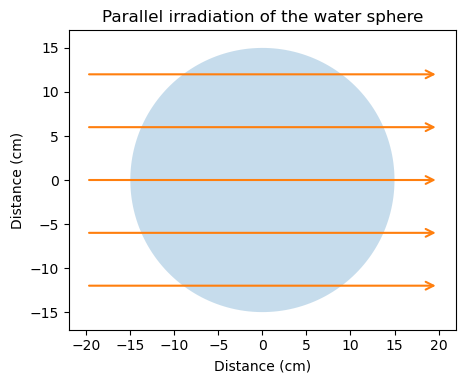

In [3]:
angle = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(5, 4))
ax.fill(radius_cm * np.cos(angle), radius_cm * np.sin(angle), alpha=0.25)
for height in [-12, -6, 0, 6, 12]:
    ax.annotate("", xy=(20, height), xytext=(-20, height),
                arrowprops={"arrowstyle": "->", "color": "tab:orange",
                            "linewidth": 1.5, "mutation_scale": 14})
ax.set(xlabel="Distance (cm)", ylabel="Distance (cm)",
       title="Parallel irradiation of the water sphere", aspect="equal",
       xlim=(-22, 22), ylim=(-17, 17))
plt.show()

## 2. Prepare and run the calibration

The library writes the water geometry and a proton source distributed uniformly
in log energy. We group the per-event deposits into ten bins per decade for
the plots below. The geometry is in centimetres, and the secondary-production
cut is 0.1 mm; the large cut used
for atmospheric layers would be unsuitable for this small phantom.

| File | What it contains |
| --- | --- |
| `calibration.gdml` | Water sphere surrounded by vacuum |
| `calibration.bins` | Energy-bin edges in MeV |
| `calibration.chunk.mac` | Proton beam, energy distribution, production cut, and events per chunk |
| `chunks.txt` | Three independently seeded jobs |
| `water-phantom.json` | Radius, density, particle, energy grid, and sampling settings |

The material is defined directly in GDML; this calculation does not need an
atmospheric PSF or an existing phantom response table.

In [4]:
energy_edges = np.geomspace(1, 1000, 31)  # MeV

prepare_water_phantom(
    run_dir, energy_edges,
    radius_cm=radius_cm,
    density_g_cm3=density_g_cm3,
    particle="proton",
    events_per_chunk=4000,
    chunks=3,
    production_cut_mm=0.1,
)

Shower output records individual transport steps. We need those steps to add up
all the energy deposited by one primary and its secondaries, including events
with no deposited energy. `atris-run` skips chunks that have already finished.

In [5]:
_ = subprocess.run(
    ["atris-run", ".", "--mode", "shower", "--physics-list", "FTFP_BERT_HP", "--quiet"],
    cwd=run_dir, check=True,
)

Each completed chunk produces a `.root` file, a log, and a `.COMPLETE` marker
inside `chunks/`. Read the raw chunks here: ordinary gathering combines
histograms but leaves out the step records needed for this calculation.

In [3]:
events = read_water_phantom_events(run_dir)
incident = events.incident_energy_MeV
deposited = events.ionizing_energy_MeV
print(f"Read {incident.size:,} incident protons")

Read 12,000 incident protons


The original phantom method uses energy deposited through ionization. The reader
also retains total deposited energy in `events.deposited_energy_MeV`, including
the non-ionizing component. Each array has one value per incoming proton after
summing the steps of that proton and all its secondaries inside the water.

At a given incident energy, different tracks leave different amounts of energy.
Here is the distribution for protons near 100 MeV.

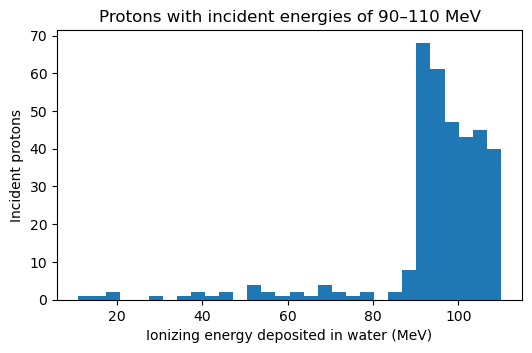

In [7]:
near_100_MeV = (incident >= 90) & (incident < 110)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(deposited[near_100_MeV], bins=30)
ax.set(xlabel="Ionizing energy deposited in water (MeV)",
       ylabel="Incident protons", title="Protons with incident energies of 90–110 MeV")
plt.show()

## 3. Calculate the response

For each proton, divide the deposited energy by its incident kinetic energy.
The mean ratio in energy bin $b$ is the dimensionless energy-response coefficient:

$$
c_b=\frac{1}{N_b}\sum_{i\in b}\frac{E_{\mathrm{ion},i}}{E_i}.
$$

A counting response answers a different question: what fraction of incident
particles produce a signal above a chosen threshold? We'll count an event if
its ionizing deposit exceeds 10 MeV. Change the threshold to see how this alters
the efficiency.

$$
\epsilon_b=\frac{\#\{i\in b:E_{\mathrm{ion},i}>E_{\mathrm{threshold}}\}}{N_b}.
$$

Count events, not individual steps or secondary particles. Events with zero
signal still belong in $N_b$.

In [4]:
fraction = deposited / incident
threshold_MeV = 10.0

counts, _ = np.histogram(incident, bins=energy_edges)
summed_fraction, _ = np.histogram(incident, bins=energy_edges, weights=fraction)
detections, _ = np.histogram(incident[deposited > threshold_MeV], bins=energy_edges)

response = np.full(counts.shape, np.nan)
efficiency = np.full(counts.shape, np.nan)
np.divide(summed_fraction, counts, out=response, where=counts > 0)
np.divide(detections, counts, out=efficiency, where=counts > 0)
energy_centres = np.sqrt(energy_edges[:-1] * energy_edges[1:])

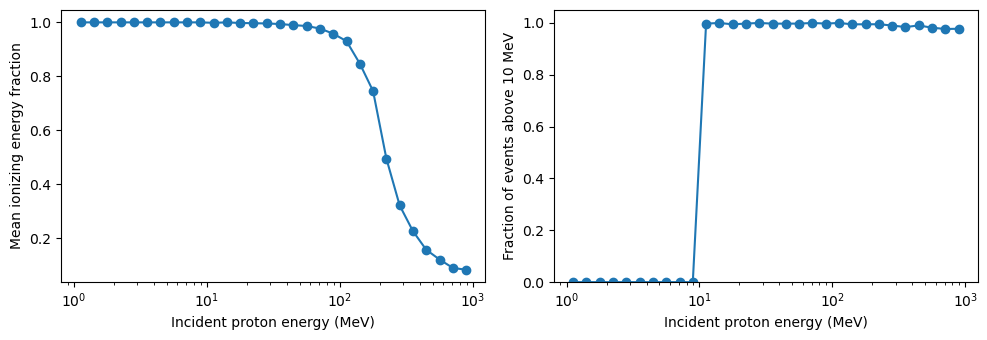

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].semilogx(energy_centres, response, "o-")
axes[0].set(xlabel="Incident proton energy (MeV)",
            ylabel="Mean ionizing energy fraction")
axes[1].semilogx(energy_centres, efficiency, "o-")
axes[1].set(xlabel="Incident proton energy (MeV)",
            ylabel=f"Fraction of events above {threshold_MeV:g} MeV", ylim=(0, 1.05))
fig.tight_layout()
plt.show()

Low-energy protons usually stop in the sphere and leave almost all their kinetic
energy there. More energetic protons can cross it and carry energy away; their
secondary particles can escape too. The counting response depends on the
threshold as well as this energy loss.

Try another radius in a new run directory, or change the threshold here without
rerunning the transport. A smaller sphere has a smaller mass and shorter paths
through water.

## 4. Compare with the supplied water phantom

The archive includes an older energy-fraction table,
`icru_zero_0.000MeV_detAB_old_response.txt`, for the unshielded water sphere.
Its header lists particle PDG codes; 2212 identifies protons. The remaining
rows contain responses on the library's fixed energy grid.

The later `icru_zero_0.000MeV_detAB_response.txt` is plotted as **absolute
ionization energy in MeV** in the [archived analysis](../reference/notebooks/explorer_v2.ipynb).
The two tables give different deposited energies, as the comparison below shows.

In [5]:
from atris_tools.phantom_tables import PhantomTable, ENERGY_CENTRES_MEV

older = PhantomTable.read(run_dir / "icru_zero_0.000MeV_detAB_old_response.txt")
later = PhantomTable.read(run_dir / "icru_zero_0.000MeV_detAB_response.txt")
proton_pdg = 2212
older_response = older.coefficients[older.pdg_codes == proton_pdg].squeeze()
# This archived table stores MeV; compare its deposited fraction explicitly.
later_energy = later.coefficients[later.pdg_codes == proton_pdg].squeeze()
later_fraction = later_energy / ENERGY_CENTRES_MEV
library_energy = ENERGY_CENTRES_MEV
in_range = (library_energy >= energy_edges[0]) & (library_energy <= energy_edges[-1])

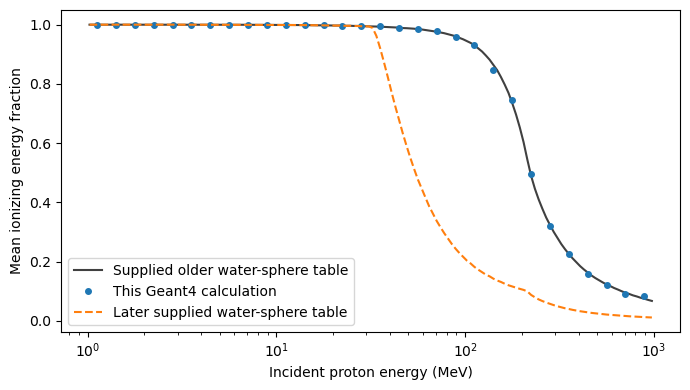

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(library_energy[in_range], older_response[in_range],
            label="Supplied older water-sphere table", color="0.25")
ax.semilogx(energy_centres, response, "o", label="This Geant4 calculation", markersize=4)
ax.semilogx(library_energy[in_range], later_fraction[in_range], "--",
            label="Later supplied water-sphere table", color="tab:orange")
ax.set(xlabel="Incident proton energy (MeV)", ylabel="Mean ionizing energy fraction")
ax.legend()
fig.tight_layout()
plt.show()

The new calculation closely follows the older water-sphere response: protons
at low energy stop in the sphere, and the deposited fraction falls as their
range becomes comparable to its diameter. The few hundred events per bin leave
some sampling scatter, especially where protons can cross the sphere.

The later table gives a substantially smaller fraction at intermediate energies.
This notebook does not reproduce that curve.
Explaining the difference requires the geometry and scoring settings used to
produce that table; matching the documented radius alone does not settle it.

## 5. Save the calibration

Keep the per-event deposits so thresholds and energy bins can be changed later.
The text file gives the plotted proton calibration, with units in the header;
`water-phantom.json` records the physical setup.

In [12]:
np.savez_compressed(
    run_dir / "water-protons-events.npz",
    incident_energy_MeV=incident,
    ionizing_energy_MeV=deposited,
    total_deposited_energy_MeV=events.deposited_energy_MeV,
)
np.savetxt(
    run_dir / "water-protons-calibration.txt",
    np.column_stack((energy_centres, counts, response, efficiency)),
    fmt=["%.3e", "%d", "%.3e", "%.3e"],
    header=f"energy_MeV  primaries  ionizing_fraction  efficiency_above_{threshold_MeV:g}_MeV",
)
_ = subprocess.run(["head", "-n", "6", "water-protons-calibration.txt"], cwd=run_dir, check=True)

# energy_MeV  primaries  ionizing_fraction  efficiency_above_10_MeV
1.122e+00 367 1.000e+00 0.000e+00
1.413e+00 400 1.000e+00 0.000e+00
1.778e+00 415 1.000e+00 0.000e+00
2.239e+00 404 1.000e+00 0.000e+00
2.818e+00 421 1.000e+00 0.000e+00


## 6. Change the incident particle

There are two source setups: a **Geant4 particle name**, or an **ion specified
by its atomic number, mass number, and charge**. The water geometry and the
response calculation stay the same. These cover the particle types in the
supplied phantom library.

### Named particles, antiparticles, and light nuclei

Pass the name as `particle`. The PDG code identifies the corresponding row
when exporting the response table.

| Type | Geant4 names | Corresponding PDG codes |
| --- | --- | --- |
| Photon | `gamma` | 22 |
| Electron and positron | `e-`, `e+` | 11, −11 |
| Muons | `mu-`, `mu+` | 13, −13 |
| Proton and antiproton | `proton`, `anti_proton` | 2212, −2212 |
| Neutron and antineutron | `neutron`, `anti_neutron` | 2112, −2112 |
| Pions | `pi+`, `pi-`, `pi0` | 211, −211, 111 |
| Charged kaons | `kaon+`, `kaon-` | 321, −321 |
| Hydrogen nuclei | `deuteron`, `triton` | 1000010020, 1000010030 |
| Helium nuclei | `He3`, `alpha` | 1000020030, 1000020040 |

Here are short runs for an electron, neutron, antiproton, charged pion, and
alpha particle. Each uses 100 incident particles between 1 MeV and 1 GeV.
These runs demonstrate source setup and reading the deposits; the full-grid
runs in the next section produce exportable tables.

In [13]:
named_sources = {
    "electron": "e-",
    "neutron": "neutron",
    "antiproton": "anti_proton",
    "pion": "pi+",
    "alpha": "alpha",
}

for label, particle in named_sources.items():
    directory = run_dir / f"source-{label}"
    directory.mkdir(exist_ok=True)
    prepare_water_phantom(
        directory, energy_edges, particle=particle,
        radius_cm=radius_cm, density_g_cm3=density_g_cm3,
        events_per_chunk=100, chunks=1,
    )
    subprocess.run(
        ["atris-run", ".", "--mode", "shower", "--physics-list", "FTFP_BERT_HP", "--quiet"],
        cwd=directory, check=True,
    )
    sample = read_water_phantom_events(directory)
    print(f"{particle}: {sample.incident_energy_MeV.size} incident particles read")

e-: 100 incident particles read


neutron: 100 incident particles read


anti_proton: 100 incident particles read


pi+: 100 incident particles read


alpha: 100 incident particles read


Antiparticles can annihilate, and unstable particles can decay. Their
secondaries are transported and included in the event's deposited energy.
Consequently, deposited energy divided by **incident kinetic energy** can
exceed one: annihilation or decay can release rest energy too. Keep those
values rather than clipping the response at one.

### Other nuclei: choose the isotope and charge

For a carbon-12 nucleus, $Z=6$ and $A=12$. We use charge $Q=6$ in units of the
elementary charge, so the incident nucleus is fully stripped. The library
writes `/gps/particle ion` followed by `/gps/ion 6 12 6 0`; the final zero
selects the nuclear ground state.

For an ordinary ground-state nucleus, the PDG code is

$$
\mathrm{PDG}=10^9+10^4Z+10A.
$$

The charge state is specified separately and is not part of that code.
Change the three values below to choose another nucleus—for example,
$Z=26$, $A=56$, $Q=26$ for fully stripped iron-56.

In [14]:
from atris_tools.particles import ion_pdg, particle_name, particle_source, pdg_code

carbon12 = {"Z": 6, "A": 12, "charge": 6}
carbon_pdg = ion_pdg(carbon12["Z"], carbon12["A"])
carbon_directory = run_dir / "source-carbon12"
carbon_directory.mkdir(exist_ok=True)

prepare_water_phantom(
    carbon_directory, energy_edges,
    particle="ion", ion=carbon12,
    radius_cm=radius_cm, density_g_cm3=density_g_cm3,
    events_per_chunk=100, chunks=1,
)
subprocess.run(
    ["atris-run", ".", "--mode", "shower", "--physics-list", "FTFP_BERT_HP", "--quiet"],
    cwd=carbon_directory, check=True,
)
carbon_events = read_water_phantom_events(carbon_directory)
print(f"Carbon-12, PDG {carbon_pdg}: {carbon_events.incident_energy_MeV.size} incident nuclei read")

Carbon-12, PDG 1000060120: 100 incident nuclei read


The energy arguments are **total kinetic energy per nucleus**, in MeV.
Thus a 120 MeV carbon-12 nucleus has 10 MeV per nucleon. If specifying a source
in MeV per nucleon, multiply its energy limits by $A$ before passing them to
this function. AtRIS's phantom response grid itself always uses total kinetic
energy, including for nuclei.

The examples above show the source variations explicitly. To calculate their
full response tables, use the same source settings on the fixed grid below.

## 7. Make loadable phantom files

AtRIS reads 650 energy bins per particle species, from 1 eV to 10 TeV. To write
a table on that grid, we need samples in every bin. We will use photons,
protons, alpha particles, and carbon-12, with 13,000 primaries of each species:
about 20 events per bin.
This is enough to exercise the whole workflow and see the response, although
bins with rare interactions will need more sampling.

The resulting phantom scores these four species. Add other sources from the
examples above to `calibration_sources` to include their contributions. Only
species in the exported header are scored.

These full-grid runs use a zero charged-particle tracking floor. Otherwise,
Geant4's default floor can stop very low-energy primaries in the vacuum before
they reach the sphere. This changes transport termination; it does not extend
the validity of the interaction models to lower energies.

`pdg_code` looks up named particles, while `ion_pdg` constructs nuclear codes.
`particle_source` turns either kind into the source arguments above. It selects
a fully stripped ion unless a different `charge` is supplied. For example, add
`"iron56": ion_pdg(26, 56)` to the dictionary below to calculate iron as well.

In [15]:
from atris_tools.phantom_calibration import (
    RESPONSE_ENERGY_EDGES_MEV,
    calibrate_water_phantom,
)

# Directory label: incident particle's PDG code.
calibration_sources = {
    "gamma": pdg_code("gamma"),
    "proton": pdg_code("proton"),
    "alpha": pdg_code("alpha"),
    "carbon12": ion_pdg(6, 12),
}

calibration_runs = {}
for label, pdg in calibration_sources.items():
    source = particle_source(pdg)
    directory = run_dir / f"full-grid-{label}"
    directory.mkdir(exist_ok=True)
    prepare_water_phantom(
        directory, RESPONSE_ENERGY_EDGES_MEV,
        radius_cm=radius_cm, density_g_cm3=density_g_cm3,
        **source, events_per_chunk=6500, chunks=2,
        production_cut_mm=0.1, tracking_floor_eV=0,
    )
    subprocess.run(
        ["atris-run", ".", "--mode", "shower", "--physics-list", "FTFP_BERT_HP", "--quiet"],
        cwd=directory, check=True,
    )
    calibration_runs[pdg] = directory

Calculate the same energy fraction and counting efficiency as above, now on
the full grid. The returned object keeps the NumPy arrays, event counts, and
sampling errors together. Photon PDG code 22 comes first because the current
AtRIS reader requires that order.

In [16]:
phantom = calibrate_water_phantom(calibration_runs, threshold_MeV=threshold_MeV)
for pdg, counts in zip(phantom.pdg_codes, phantom.sample_counts):
    print(f"PDG {pdg}: {counts.sum():,} primaries; {counts.min()}–{counts.max()} per bin")

PDG 22: 13,000 primaries; 7–33 per bin
PDG 2212: 13,000 primaries; 5–34 per bin
PDG 1000020040: 13,000 primaries; 8–33 per bin
PDG 1000060120: 13,000 primaries; 6–34 per bin


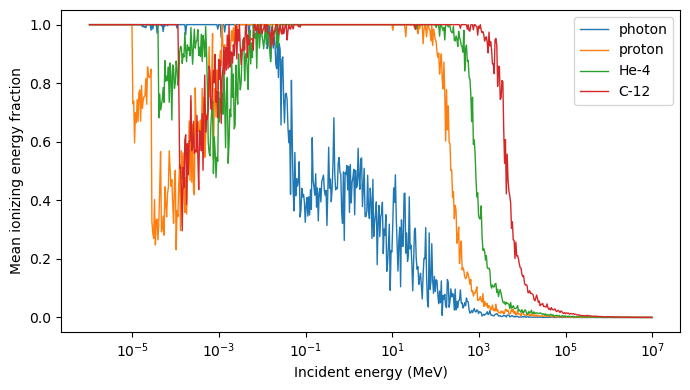

In [17]:
full_energy = np.sqrt(RESPONSE_ENERGY_EDGES_MEV[:-1] * RESPONSE_ENERGY_EDGES_MEV[1:])
fig, ax = plt.subplots(figsize=(7, 4))
for pdg, fraction in zip(phantom.pdg_codes, phantom.energy_fraction):
    label = particle_name(pdg)
    ax.semilogx(full_energy, fraction, label=label, linewidth=1)
ax.set(xlabel="Incident energy (MeV)", ylabel="Mean ionizing energy fraction")
ax.legend()
fig.tight_layout()
plt.show()

Write both tables and the matching selection file. The energy table contains
fractions; the counting table uses the 10 MeV deposited-energy threshold set
above. The writer refuses to export unsampled bins rather than turning them
into zero response. If that happens, add calibration chunks and recalculate.

| File | Contents |
| --- | --- |
| `water-sphere_response.txt` | PDG header followed by 650 mean energy fractions for each species |
| `water-sphere_counting.txt` | Same header and layout, with counting efficiencies |
| `phantoms.txt` | File stem, sphere mass, and effective area $2\pi r^2$ |
| `water-sphere_sampling.npz` | Bin edges, event counts, and standard errors of the mean fractions |
| `water-sphere_calibration.json` | Radius, density, threshold, and included species |

Each table records its quantity in a comment before the PDG header.
AtRIS and the plotting tools read these files through the same unit convention.
The standard four-panel plot shows deposited energy in MeV; the fraction plots
above show that energy divided by the incoming particle energy.

The small matrices are directly readable by AtRIS. The sampling and metadata
files stay beside them for later inspection.

In [8]:
phantom_directory = run_dir / "phantom-files"
phantom.write(phantom_directory, stem="water-sphere", fmt="%.8e")
print((phantom_directory / "phantoms.txt").read_text())
for suffix in ["response", "counting"]:
    path = phantom_directory / f"water-sphere_{suffix}.txt"
    table = PhantomTable.read(path, counting=suffix == "counting")
    print(f"{path.name}: {table.coefficients.shape}")

# ID stem mass_g area_cm2
0 water-sphere 14094.7554403 1413.71669412

water-sphere_response.txt: (4, 650)
water-sphere_counting.txt: (4, 650)


## 8. Load the phantom in an atmospheric run

In your prepared atmospheric run directory, before starting its chunks, copy the two tables and
`phantoms.txt` from `phantom-files/`. The following assumes that the tutorial
run is in the sibling directory `../water-phantom`; adjust that source path
if you put it elsewhere.

```bash
cp ../water-phantom/phantom-files/water-sphere_response.txt .
cp ../water-phantom/phantom-files/water-sphere_counting.txt .
cp ../water-phantom/phantom-files/phantoms.txt .
atris-stage-phantoms .
atris-run . --entry 1
atris-gather .
atris-postprocess .
```

This `phantoms.txt` selects the new sphere as the only phantom. After
post-processing, `.dose0`, `.equi0`, and `.rates0` contain its responses.
With this four-species table, they include photon, proton, alpha, and carbon-12
contributions.
Use the [spectrum-folding notebook](earth-spectrum-folding.ipynb) to turn
those response functions into rates for an incident spectrum.

To include more species, add their source settings and PDG codes to
`calibration_sources` and rerun the full-grid cells. To improve sampling,
increase `chunks` in the full-grid preparation cell and
rerun it. The library appends new seed pairs, keeps completed chunks, and
recalculates the tables from all completed calibration events.